In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import arviz as az
import pymc as pm
import matplotlib.pyplot as plt
import pytensor.tensor as pt
from ovca.patient import Schedule, time_on
from ovca.config import DAYS_PER_MONTH
from ovca import config as C
from ovca.models.growth_death import LOG_CAP

In [2]:
ca125_dataset = pd.read_csv("data/synthetic_data.csv")

In [3]:
patient_id = "SYN08"  # Change this to fit another patient.
patient_data = ca125_dataset.loc[ca125_dataset["patient"] == patient_id].copy()
if patient_data.empty:
    raise ValueError(f"No data found for patient {patient_id!r}.")
# The source has daily rows, but only visit days are actual clinic readings.
patient_data["month"] = patient_data["time"] / DAYS_PER_MONTH
patient_data = patient_data.rename(columns={"CA125": "ca125"})
display(patient_data.loc[patient_data["visit"] == 1])


,tumor_burden,ca125,time,treatment_applied,patient,model,cohort_seed,patient_seed,phase,noise_sd_log,...,ca125_0,q_surgery,nact_starts,t_surgery,act_starts,t_end,true_recurrence_abs,true_recurrence_rel,t_detected,month
9847,435.60800,395.01800,0,1,SYN08,growth_death,1,2037209174,pre,0.15,...,435.608,0.094172,0.0000;1.0000;2.0000;3.0000,6,7.0000;8.0000;9.0000,10,23.93,13.93,24.9667,0.000000
9877,241.69000,237.22500,30,1,SYN08,growth_death,1,2037209174,pre,0.15,...,435.608,0.094172,0.0000;1.0000;2.0000;3.0000,6,7.0000;8.0000;9.0000,10,23.93,13.93,24.9667,1.000000
9907,134.09800,155.75700,60,1,SYN08,growth_death,1,2037209174,pre,0.15,...,435.608,0.094172,0.0000;1.0000;2.0000;3.0000,6,7.0000;8.0000;9.0000,10,23.93,13.93,24.9667,2.000000
9937,74.40230,71.94170,90,1,SYN08,growth_death,1,2037209174,pre,0.15,...,435.608,0.094172,0.0000;1.0000;2.0000;3.0000,6,7.0000;8.0000;9.0000,10,23.93,13.93,24.9667,3.000000
10024,57.04710,47.03040,177,0,SYN08,growth_death,1,2037209174,pre,0.15,...,435.608,0.094172,0.0000;1.0000;2.0000;3.0000,6,7.0000;8.0000;9.0000,10,23.93,13.93,24.9667,5.900000
10042,5.98477,5.03670,195,0,SYN08,growth_death,1,2037209174,post,0.15,...,435.608,0.094172,0.0000;1.0000;2.0000;3.0000,6,7.0000;8.0000;9.0000,10,23.93,13.93,24.9667,6.500000
10057,6.55459,5.86293,210,1,SYN08,growth_death,1,2037209174,post,0.15,...,435.608,0.094172,0.0000;1.0000;2.0000;3.0000,6,7.0000;8.0000;9.0000,10,23.93,13.93,24.9667,7.000000
10087,4.92548,4.20447,240,1,SYN08,growth_death,1,2037209174,post,0.15,...,435.608,0.094172,0.0000;1.0000;2.0000;3.0000,6,7.0000;8.0000;9.0000,10,23.93,13.93,24.9667,8.000000
10117,3.70128,3.92020,270,1,SYN08,growth_death,1,2037209174,post,0.15,...,435.608,0.094172,0.0000;1.0000;2.0000;3.0000,6,7.0000;8.0000;9.0000,10,23.93,13.93,24.9667,9.000000
10147,2.78134,3.42662,300,0,SYN08,growth_death,1,2037209174,post,0.15,...,435.608,0.094172,0.0000;1.0000;2.0000;3.0000,6,7.0000;8.0000;9.0000,10,23.93,13.93,24.9667,10.000000


## Bayesian two-phase model

The likelihood uses all pre-surgery clinic visits and the first three post-surgery visits. Times are converted from days to months. Each phase follows `dT/dt = (b - d * D(t)) * T`, with separate growth and death rates and treatment intervals. The post-surgery trajectory starts at an independently estimated level `T_post0` at the surgery time. The model uses the generator's numerical cap and log-normal observation noise, with the known noise standard deviation from the file.

The priors use the generator's correlated log-normal rate population and baseline distribution, conditioned on its pre-surgery minimum gate. `T_post0` has an independent log-normal prior with median 100 U/mL and log-scale standard deviation 1.5. This replaces the generator's surgery-fraction distribution and jump gate, so the fitted prior is no longer identical to the generator's joint distribution across surgery. This assumes the file was generated with the current `ovca.config` settings. No true patient parameter values or tumour-burden values are used in fitting. The selected early visits are before surveillance, so the later recurrence-dependent stopping rule does not enter this likelihood.


In [5]:
# Schedule columns are constant across the selected patient's daily rows.
schedule_columns = ["nact_starts", "t_surgery", "act_starts", "noise_sd_log", "model"]
if len(patient_data[schedule_columns].drop_duplicates()) != 1:
    raise ValueError("Expected one consistent treatment schedule for the selected patient.")
schedule = Schedule.from_record(patient_data.iloc[0])
if patient_data.iloc[0]["model"] != "growth_death":
    raise ValueError("This notebook requires data generated by the growth_death model.")
noise_sd = float(patient_data.iloc[0]["noise_sd_log"])
if not np.isfinite(noise_sd) or noise_sd <= 0:
    raise ValueError("The observation noise standard deviation must be positive.")

n_post_surgery_obs = 3  # Use only the first three post-surgery clinic readings.
visits = patient_data.loc[patient_data["visit"] == 1].sort_values("month")
if not set(visits["phase"]).issubset({"pre", "post"}):
    raise ValueError("Visit phases must be 'pre' or 'post'.")
observations = pd.concat([
    visits.loc[visits["phase"] == "pre"],
    visits.loc[visits["phase"] == "post"].head(n_post_surgery_obs),
]).sort_values("month").reset_index(drop=True)
if observations.empty or observations["ca125"].isna().any() or (observations["ca125"] <= 0).any():
    raise ValueError("The log-normal likelihood requires positive, non-missing readings.")

times = observations["month"].to_numpy(dtype=float)
is_pre = observations["phase"].eq("pre").to_numpy()
if not is_pre.any() or is_pre.all():
    raise ValueError("The selected patient needs visits in both phases.")
t0 = 0.0  # The generator defines ca125_0 at the first NACT cycle (month 0).
ts = schedule.t_surgery
if np.any(times[is_pre] > ts) or np.any(times[~is_pre] < ts):
    raise ValueError("Visit phases must agree with the surgery time.")

# time_on integrates the union of treatment intervals, avoiding double counting.
pre_times = times[is_pre]
post_times = times[~is_pre]
exposure = time_on(pre_times, t0, schedule.intervals("pre"))
post_exposure = time_on(post_times, ts, schedule.intervals("post"))

# The generator checks this same grid, including the instant just before surgery.
gate_times = np.append(np.arange(0.0, ts, 0.05), ts - 1e-9)
gate_exposure = time_on(gate_times, t0, schedule.intervals("pre"))


In [7]:
patient_data

,tumor_burden,ca125,time,treatment_applied,patient,model,cohort_seed,patient_seed,phase,noise_sd_log,...,ca125_0,q_surgery,nact_starts,t_surgery,act_starts,t_end,true_recurrence_abs,true_recurrence_rel,t_detected,month
9847,435.608,395.018,0,1,SYN08,growth_death,1,2037209174,pre,0.15,...,435.608,0.094172,0.0000;1.0000;2.0000;3.0000,6,7.0000;8.0000;9.0000,10,23.93,13.93,24.9667,0.000000
9848,427.138,522.991,1,1,SYN08,growth_death,1,2037209174,pre,0.15,...,435.608,0.094172,0.0000;1.0000;2.0000;3.0000,6,7.0000;8.0000;9.0000,10,23.93,13.93,24.9667,0.033333
9849,418.832,514.375,2,1,SYN08,growth_death,1,2037209174,pre,0.15,...,435.608,0.094172,0.0000;1.0000;2.0000;3.0000,6,7.0000;8.0000;9.0000,10,23.93,13.93,24.9667,0.066667
9850,410.688,563.363,3,1,SYN08,growth_death,1,2037209174,pre,0.15,...,435.608,0.094172,0.0000;1.0000;2.0000;3.0000,6,7.0000;8.0000;9.0000,10,23.93,13.93,24.9667,0.100000
9851,402.702,428.833,4,1,SYN08,growth_death,1,2037209174,pre,0.15,...,435.608,0.094172,0.0000;1.0000;2.0000;3.0000,6,7.0000;8.0000;9.0000,10,23.93,13.93,24.9667,0.133333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11223,1895.090,1757.190,1376,0,SYN08,growth_death,1,2037209174,post,0.15,...,435.608,0.094172,0.0000;1.0000;2.0000;3.0000,6,7.0000;8.0000;9.0000,10,23.93,13.93,24.9667,45.866667
11224,1906.620,1601.940,1377,0,SYN08,growth_death,1,2037209174,post,0.15,...,435.608,0.094172,0.0000;1.0000;2.0000;3.0000,6,7.0000;8.0000;9.0000,10,23.93,13.93,24.9667,45.900000
11225,1918.210,1763.640,1378,0,SYN08,growth_death,1,2037209174,post,0.15,...,435.608,0.094172,0.0000;1.0000;2.0000;3.0000,6,7.0000;8.0000;9.0000,10,23.93,13.93,24.9667,45.933333
11226,1929.880,1604.200,1379,0,SYN08,growth_death,1,2037209174,post,0.15,...,435.608,0.094172,0.0000;1.0000;2.0000;3.0000,6,7.0000;8.0000;9.0000,10,23.93,13.93,24.9667,45.966667


In [ ]:
# The population covariance is on the log scale, in the order listed in config.
pop = C.POPULATION["growth_death"]
rate_names = ["gamma_pre", "delta_pre", "gamma_post", "delta_post"]
rate_sd = np.asarray(pop["sd_log"])
rate_cov = np.outer(rate_sd, rate_sd) * pop["corr"]

with pm.Model() as model:
    log_rates = pm.MvNormal("log_rates", mu = np.log(pop["median"]), cov = rate_cov, shape = 4)
    # pre surgery 
    b_pre = pm.Deterministic("b_pre", pt.exp(log_rates[0]))
    d_pre = pm.Deterministic("d_pre", pt.exp(log_rates[1]))
    b_post = pm.Deterministic("b_post", pt.exp(log_rates[2]))
    d_post = pm.Deterministic("d_post", pt.exp(log_rates[3]))
    T0 = pm.LogNormal("T0", mu = np.log(patient_data["ca125"].iloc[0]), sigma = C.CA125_0_SD_LOG)
    # Independent prior for the level immediately after surgery (U/mL).
    T_post0 = pm.LogNormal("T_post0", mu = np.log(100.0), sigma = 1.5)

    log_T_pre = pt.minimum(pt.log(T0) + b_pre * (pre_times - t0) - d_pre * exposure, LOG_CAP)
    log_T_post = pt.minimum(pt.log(T_post0) + b_post * (post_times - ts)
                            - d_post * post_exposure, LOG_CAP)
    log_T_gate = pt.minimum(pt.log(T0) + b_pre * gate_times - d_pre * gate_exposure, LOG_CAP)
    pm.Potential("pre_surgery_gate", pt.switch(pt.min(log_T_gate) >= np.log(C.PRE_SURGERY_MIN), 0.0, -np.inf))
    pm.LogNormal("y_pre", mu=log_T_pre, sigma=noise_sd,
                 observed=observations.loc[is_pre, "ca125"].to_numpy())
    pm.LogNormal("y_post", mu=log_T_post, sigma=noise_sd,
                 observed=observations.loc[~is_pre, "ca125"].to_numpy())
    idata = pm.sample(draws=1000, tune=1000, chains=4, target_accept=0.99, random_seed = 2026)
    pm.sample_posterior_predictive(idata, extend_inferencedata = True, random_seed = 2026)

az.summary(idata, var_names=["b_pre", "d_pre", "b_post", "d_post", "T0", "T_post0"])


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [log_rates, T0, T_post0]


/Users/lotta/.pyenv/versions/3.11.14/lib/python3.11/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 4 seconds.
There were 379 divergences after tuning. Increase `target_accept` or reparameterize.
/var/folders/ml/2w7_tlz90j9142hp2nlzzrc40000gn/T/ipykernel_44197/1547239525.py:27: UserWarning: The effect of Potentials on other parameters is ignored during posterior predictive sampling. This is likely to lead to invalid or biased predictive samples.
  pm.sample_posterior_predictive(idata, extend_inferencedata = True, random_seed = 2026)
Sampling: [y_post, y_pre]


/Users/lotta/.pyenv/versions/3.11.14/lib/python3.11/site-packages/rich/live.py:260: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
b_pre,0.109,0.039,0.049,0.185,0.001,0.001,1189.0,1363.0,1.0
d_pre,0.709,0.064,0.591,0.832,0.002,0.001,1284.0,1304.0,1.0
b_post,0.109,0.047,0.031,0.192,0.001,0.002,1524.0,1279.0,1.0
d_post,0.419,0.080,0.274,0.563,0.002,0.001,2272.0,2406.0,1.0
T0,440.254,49.278,352.740,534.460,1.157,1.097,1865.0,1642.0,1.0
T_post0,5.134,0.525,4.160,6.131,0.012,0.010,2027.0,1621.0,1.0


### Posterior uncertainty over time

The darker band is a 95% posterior credible interval for the underlying trajectory; the lighter band is a 95% posterior predictive interval for a new noisy CA-125 reading. The plot extends 10 months beyond the last observation used in the fit; this portion is a model-based extrapolation. The pre- and post-surgery levels are estimated separately, so lines between them are intentionally omitted.

The dashed red line shows the noise-free trajectory saved in the synthetic dataset; it is not used for fitting.


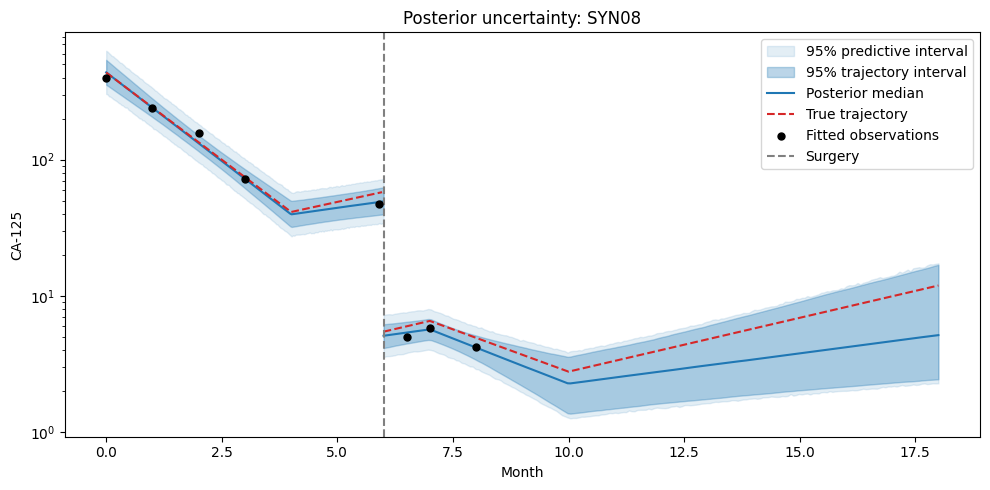

In [19]:
# Flatten chains and draws together, preserving each draw's parameter values.
posterior = idata.posterior.stack(sample=("chain", "draw"))
b_pre_draw = posterior["b_pre"].values[:, None]
d_pre_draw = posterior["d_pre"].values[:, None]
b_post_draw = posterior["b_post"].values[:, None]
d_post_draw = posterior["d_post"].values[:, None]
T0_draw = posterior["T0"].values[:, None]
T_post0_draw = posterior["T_post0"].values[:, None]


pre_grid = np.linspace(t0, ts, 200)
post_grid = np.linspace(ts, post_times.max() + 10, 200)
pre_exposure = time_on(pre_grid, t0, schedule.intervals("pre"))
post_exposure_grid = time_on(post_grid, ts, schedule.intervals("post"))
log_pre_curves = np.minimum(np.log(T0_draw) + b_pre_draw * (pre_grid - t0)
                            - d_pre_draw * pre_exposure, LOG_CAP)
log_post_curves = np.minimum(np.log(T_post0_draw)
                             + b_post_draw * (post_grid - ts)
                             - d_post_draw * post_exposure_grid, LOG_CAP)
pre_curves = np.exp(log_pre_curves)
post_curves = np.exp(log_post_curves)

rng = np.random.default_rng(2026)
fig, ax = plt.subplots(figsize=(10, 5))
for grid, curves, label in [(pre_grid, pre_curves, "Pre-surgery"),
                            (post_grid, post_curves, "Post-surgery")]:
    predictive = curves * np.exp(rng.normal(size=curves.shape) * noise_sd)
    lo_pred, hi_pred = np.quantile(predictive, [0.025, 0.975], axis=0)
    lo, median, hi = np.quantile(curves, [0.025, 0.5, 0.975], axis=0)
    ax.fill_between(grid, lo_pred, hi_pred, color="C0", alpha=0.12,
                    label="95% predictive interval" if label == "Pre-surgery" else None)
    ax.fill_between(grid, lo, hi, color="C0", alpha=0.3,
                    label="95% trajectory interval" if label == "Pre-surgery" else None)
    ax.plot(grid, median, color="C0", label="Posterior median" if label == "Pre-surgery" else None)
# The saved noise-free trajectory is shown for comparison only; it is not fitted.
truth = patient_data.loc[patient_data["month"] <= post_grid[-1]].sort_values("month")
for phase in ("pre", "post"):
    segment = truth.loc[truth["phase"] == phase]
    ax.plot(segment["month"], segment["tumor_burden"], color="C3", linestyle="--",
            label="True trajectory" if phase == "pre" else None)
ax.scatter(times, observations["ca125"], color="black", s=25, zorder=3, label="Fitted observations")
ax.axvline(ts, color="grey", linestyle="--", label="Surgery")
ax.set(xlabel="Month", ylabel="CA-125", title=f"Posterior uncertainty: {patient_id}", yscale="log")
ax.legend()
fig.tight_layout()
plt.show()


Divergent transitions: 405 of 4000 draws


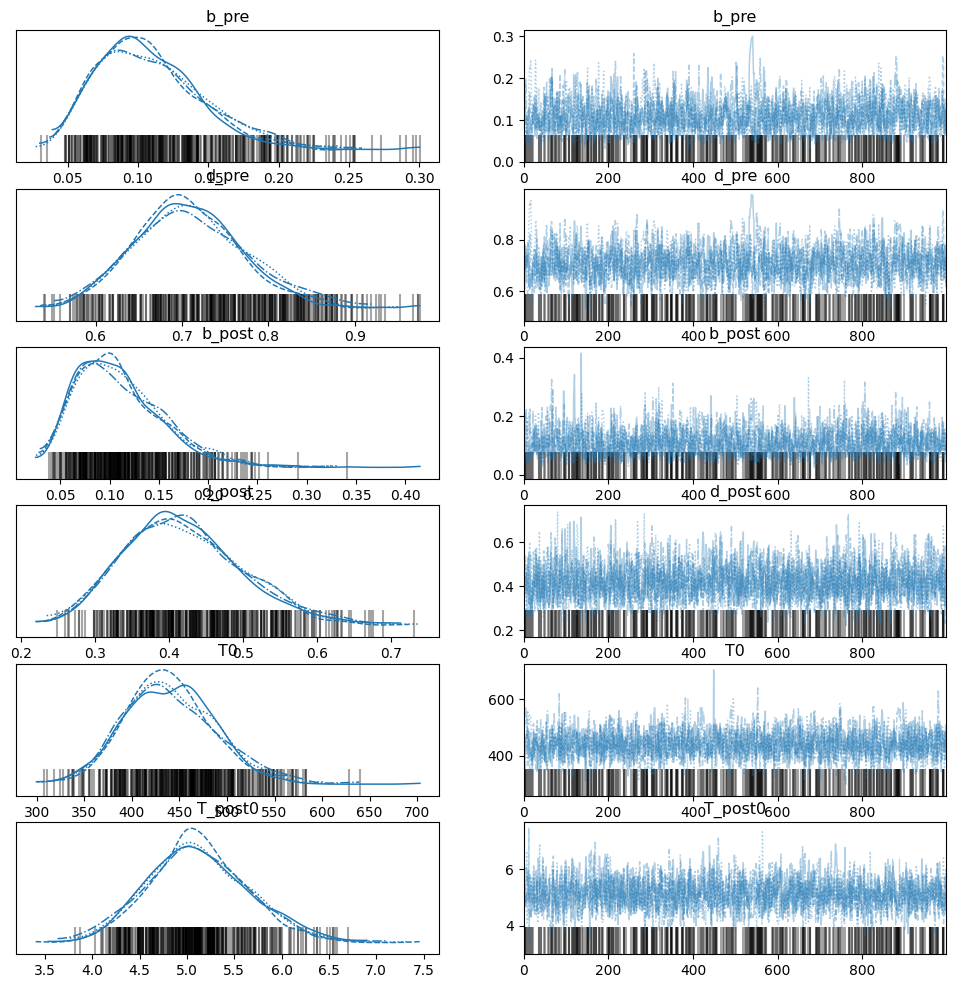

In [14]:
az.plot_trace(idata, var_names=["b_pre", "d_pre", "b_post", "d_post", "T0", "T_post0"]);
print(f"Divergent transitions: {int(idata.sample_stats['diverging'].sum())} "
      f"of {idata.sample_stats['diverging'].size} draws")


In [ ]:
# TODO : add a new observation at a future time, how does the uncertainity change